In [ ]:
# Test VENV to ensure that correct one is in use
import sys 
print(sys.executable)

import tensorflow as tf
from tensorflow.keras import layers, models

# Load MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalise pixel values to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension: (28, 28) -> (28, 28, 1)
x_train = x_train[..., tf.newaxis]
x_test = x_test[..., tf.newaxis]

# Build CNN
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

# Evaluate
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print(f"Test accuracy: {test_accuracy:.4f}")

/Users/dwaynecruz/Desktop/EP Pt. A Files/.venv(tensorflow)/bin/python


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.9204 - loss: 0.2606 - val_accuracy: 0.9818 - val_loss: 0.0621
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9767 - loss: 0.0785 - val_accuracy: 0.9892 - val_loss: 0.0391
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9827 - loss: 0.0558 - val_accuracy: 0.9898 - val_loss: 0.0378
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9865 - loss: 0.0443 - val_accuracy: 0.9902 - val_loss: 0.0367
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9883 - loss: 0.0371 - val_accuracy: 0.9913 - val_loss: 0.0319
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1258s 3s/step - accuracy: 0.9905 - loss: 0.0306 - val_accuracy: 0.9920 - val_loss: 0.0323
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.9909 - loss: 0.0279 - val_accuracy: 0.9912 - val_loss: 0.0318
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.9926 - loss: 0.0227 - va

In [ ]:
# Evaluate
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print(f"Test accuracy: {test_accuracy:.4f}")

# Save trained model
MODEL_PATH = "mnist_cnn_baseline.keras"
model.save(MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9923 - loss: 0.0234
Test accuracy: 0.9923
Model saved to: mnist_cnn_baseline.keras


In [12]:
import time
import numpy as np

sample = x_test[0:1]

# Warm-up
for _ in range(10):
    model.predict(sample, verbose=0)

times = []

for i in range(100):
    sample = x_test[i:i+1]

    start = time.perf_counter()
    model.predict(sample, verbose=0)
    end = time.perf_counter()

    times.append((end - start) * 1000)

print(f"Average inference latency: {np.mean(times):.2f} ms")
print(f"Minimum latency: {np.min(times):.2f} ms")
print(f"Maximum latency: {np.max(times):.2f} ms")

Average inference latency: 28.90 ms
Minimum latency: 26.92 ms
Maximum latency: 31.77 ms


Clean MNIST     | Accuracy: 99.23% | Loss: 0.0234
Gaussian Noise  | Accuracy: 98.52% | Loss: 0.0526
Shifted         | Accuracy: 86.28% | Loss: 0.5592
Blurred         | Accuracy: 98.79% | Loss: 0.0380


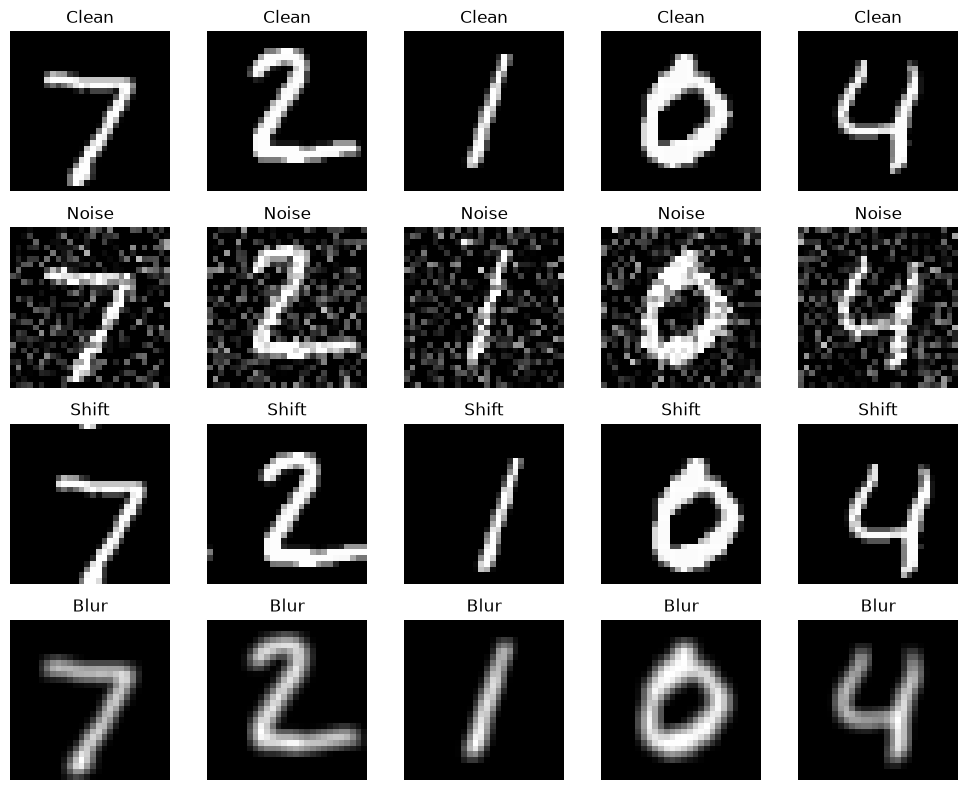

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load your saved baseline model
model = tf.keras.models.load_model("mnist_cnn_baseline.keras")

# Load MNIST test set
(_, _), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_test = x_test.astype("float32") / 255.0
x_test = np.expand_dims(x_test, axis=-1)


# --------------------------------------------------
# 1. Add Gaussian noise
# --------------------------------------------------

def add_gaussian_noise(images, noise_level=0.25):
    noise = np.random.normal(
        loc=0.0,
        scale=noise_level,
        size=images.shape
    )

    noisy = images + noise

    return np.clip(noisy, 0.0, 1.0)


# --------------------------------------------------
# 2. Random translation
# --------------------------------------------------

def translate_images(images, shift_x=2, shift_y=2):
    translated = tf.roll(
        images,
        shift=[shift_y, shift_x],
        axis=[1, 2]
    )

    return translated.numpy()


# --------------------------------------------------
# 3. Blur images
# --------------------------------------------------

def blur_images(images):
    # Simple 3x3 average blur
    kernel = np.ones((3, 3, 1, 1), dtype=np.float32) / 9.0

    blurred = tf.nn.conv2d(
        images,
        kernel,
        strides=1,
        padding="SAME"
    )

    return blurred.numpy()


# --------------------------------------------------
# 4. Create degraded datasets
# --------------------------------------------------

x_noise = add_gaussian_noise(
    x_test,
    noise_level=0.25
)

x_shift = translate_images(
    x_test,
    shift_x=2,
    shift_y=2
)

x_blur = blur_images(
    x_test
)


# --------------------------------------------------
# 5. Evaluate each condition
# --------------------------------------------------

datasets = {
    "Clean MNIST": x_test,
    "Gaussian Noise": x_noise,
    "Shifted": x_shift,
    "Blurred": x_blur
}

results = {}

for name, data in datasets.items():

    loss, accuracy = model.evaluate(
        data,
        y_test,
        verbose=0
    )

    results[name] = {
        "loss": loss,
        "accuracy": accuracy
    }

    print(
        f"{name:15s} | "
        f"Accuracy: {accuracy * 100:.2f}% | "
        f"Loss: {loss:.4f}"
    )


# --------------------------------------------------
# 6. Visualise examples
# --------------------------------------------------

plt.figure(figsize=(10, 8))

for i in range(5):

    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title("Clean")
    plt.axis("off")

    plt.subplot(4, 5, i + 6)
    plt.imshow(x_noise[i].squeeze(), cmap="gray")
    plt.title("Noise")
    plt.axis("off")

    plt.subplot(4, 5, i + 11)
    plt.imshow(x_shift[i].squeeze(), cmap="gray")
    plt.title("Shift")
    plt.axis("off")

    plt.subplot(4, 5, i + 16)
    plt.imshow(x_blur[i].squeeze(), cmap="gray")
    plt.title("Blur")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [1]:
import cv2
import numpy as np
import tensorflow as tf


# -------------------------------------------------------
# 1. Load trained MNIST CNN
# -------------------------------------------------------

MODEL_PATH = "mnist_cnn_baseline.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")


# -------------------------------------------------------
# 2. Preprocess camera image to look like MNIST
# -------------------------------------------------------

def preprocess_digit(roi):

    # Convert camera image to grayscale
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    # Blur slightly to reduce camera noise
    blurred = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    # Convert paper + dark writing into
    # white digit + black background
    _, threshold = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Find contours
    contours, _ = cv2.findContours(
        threshold,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        return None, threshold

    # Find largest object in the ROI
    largest_contour = max(
        contours,
        key=cv2.contourArea
    )

    # Ignore very small objects/noise
    if cv2.contourArea(largest_contour) < 500:
        return None, threshold

    # Bounding box around digit
    x, y, w, h = cv2.boundingRect(
        largest_contour
    )

    digit = threshold[
        y:y+h,
        x:x+w
    ]

    # ---------------------------------------------------
    # Preserve aspect ratio
    # ---------------------------------------------------

    target_size = 20

    if h > w:

        new_h = target_size
        new_w = max(
            1,
            int(w * target_size / h)
        )

    else:

        new_w = target_size
        new_h = max(
            1,
            int(h * target_size / w)
        )

    digit = cv2.resize(
        digit,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    # ---------------------------------------------------
    # Place digit in centre of 28x28 image
    # ---------------------------------------------------

    canvas = np.zeros(
        (28, 28),
        dtype=np.uint8
    )

    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = digit

    # Convert pixels from 0-255 to 0-1
    canvas = canvas.astype(
        "float32"
    ) / 255.0

    # CNN input shape:
    # (batch, height, width, channel)
    model_input = canvas.reshape(
        1,
        28,
        28,
        1
    )

    return model_input, canvas


# -------------------------------------------------------
# 3. Open laptop camera
# -------------------------------------------------------

camera = cv2.VideoCapture(0)

if not camera.isOpened():
    raise RuntimeError(
        "Could not open camera."
    )


# -------------------------------------------------------
# 4. Camera loop
# -------------------------------------------------------

while True:

    ret, frame = camera.read()

    if not ret:
        break

    frame = cv2.flip(
        frame,
        1
    )

    height, width, _ = frame.shape


    # ---------------------------------------------------
    # Detection region in centre of screen
    # ---------------------------------------------------

    box_size = 300

    x1 = width // 2 - box_size // 2
    y1 = height // 2 - box_size // 2

    x2 = x1 + box_size
    y2 = y1 + box_size

    roi = frame[
        y1:y2,
        x1:x2
    ]


    # ---------------------------------------------------
    # Preprocess digit
    # ---------------------------------------------------

    processed, preview = preprocess_digit(
        roi
    )


    # ---------------------------------------------------
    # CNN prediction
    # ---------------------------------------------------

    prediction_text = "No digit detected"

    if processed is not None:

        predictions = model.predict(
            processed,
            verbose=0
        )

        predicted_digit = np.argmax(
            predictions[0]
        )

        confidence = np.max(
            predictions[0]
        )

        prediction_text = (
            f"Digit: {predicted_digit} "
            f"Confidence: {confidence * 100:.1f}%"
        )


    # ---------------------------------------------------
    # Draw detection box
    # ---------------------------------------------------

    cv2.rectangle(
        frame,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )


    # ---------------------------------------------------
    # Show prediction
    # ---------------------------------------------------

    cv2.putText(
        frame,
        prediction_text,
        (30, 50),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )

    cv2.putText(
        frame,
        "Place one handwritten digit inside box",
        (30, height - 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )


    # ---------------------------------------------------
    # Display camera
    # ---------------------------------------------------

    cv2.imshow(
        "Handwritten Digit Recognition",
        frame
    )

    if processed is not None:

        # Scale preview so it is easier to see
        preview_large = cv2.resize(
            preview,
            (280, 280),
            interpolation=cv2.INTER_NEAREST
        )

        cv2.imshow(
            "CNN Input",
            preview_large
        )


    # Press Q to exit
    key = cv2.waitKey(1) & 0xFF

    if key == ord("q"):
        break


# -------------------------------------------------------
# 5. Cleanup
# -------------------------------------------------------

camera.release()
cv2.destroyAllWindows()

Model loaded successfully.


KeyboardInterrupt: 

In [ ]:
import cv2
import numpy as np
import tensorflow as tf


# ============================================================
# 1. LOAD TRAINED CNN MODEL
# ============================================================

MODEL_PATH = "mnist_cnn_baseline.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")


# ============================================================
# 2. PREPROCESS DIGIT
# ============================================================

def preprocess_digit(roi):

    # Convert to grayscale
    gray = cv2.cvtColor(
        roi,
        cv2.COLOR_BGR2GRAY
    )

    # Reduce noise
    blurred = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    # Turn black writing on white paper
    # into white digit on black background
    _, threshold = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Find contours
    contours, _ = cv2.findContours(
        threshold,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        return None, threshold

    # Largest contour assumed to be the digit
    largest_contour = max(
        contours,
        key=cv2.contourArea
    )

    # Ignore very small objects
    if cv2.contourArea(largest_contour) < 500:
        return None, threshold

    # Bounding box
    x, y, w, h = cv2.boundingRect(
        largest_contour
    )

    digit = threshold[
        y:y + h,
        x:x + w
    ]

    # --------------------------------------------------------
    # Resize while preserving aspect ratio
    # --------------------------------------------------------

    target_size = 20

    if h > w:

        new_h = target_size
        new_w = max(
            1,
            int(w * target_size / h)
        )

    else:

        new_w = target_size
        new_h = max(
            1,
            int(h * target_size / w)
        )

    digit = cv2.resize(
        digit,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    # --------------------------------------------------------
    # Centre on 28x28 MNIST canvas
    # --------------------------------------------------------

    canvas = np.zeros(
        (28, 28),
        dtype=np.uint8
    )

    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = digit

    # Normalise
    canvas_float = canvas.astype(
        "float32"
    ) / 255.0

    # CNN input shape
    model_input = canvas_float.reshape(
        1,
        28,
        28,
        1
    )

    return model_input, canvas


# ============================================================
# 3. OPEN MACBOOK WEBCAM
# ============================================================

camera = cv2.VideoCapture(0)

if not camera.isOpened():
    raise RuntimeError(
        "Could not open MacBook webcam."
    )

print("MacBook webcam opened.")
print("Press Q to quit.")


# ============================================================
# 4. LIVE CAMERA LOOP
# ============================================================

while True:

    ret, frame = camera.read()

    if not ret:
        continue

    # Mirror camera
    frame = cv2.flip(
        frame,
        1
    )

    height, width, _ = frame.shape


    # --------------------------------------------------------
    # Centre box
    # --------------------------------------------------------

    box_size = 300

    x1 = width // 2 - box_size // 2
    y1 = height // 2 - box_size // 2

    x2 = x1 + box_size
    y2 = y1 + box_size

    roi = frame[
        y1:y2,
        x1:x2
    ]


    # --------------------------------------------------------
    # Preprocess
    # --------------------------------------------------------

    processed, preview = preprocess_digit(
        roi
    )

    prediction_text = "No digit detected"


    # --------------------------------------------------------
    # CNN Prediction
    # --------------------------------------------------------

    if processed is not None:

        predictions = model.predict(
            processed,
            verbose=0
        )

        predicted_digit = int(
            np.argmax(predictions[0])
        )

        confidence = float(
            np.max(predictions[0])
        )

        prediction_text = (
            f"Digit: {predicted_digit} "
            f"Confidence: {confidence * 100:.1f}%"
        )


    # --------------------------------------------------------
    # Draw centre box
    # --------------------------------------------------------

    cv2.rectangle(
        frame,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )


    # --------------------------------------------------------
    # Display prediction
    # --------------------------------------------------------

    cv2.putText(
        frame,
        prediction_text,
        (30, 50),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )

    cv2.putText(
        frame,
        "Place one handwritten digit inside box",
        (30, height - 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )


    # --------------------------------------------------------
    # Show webcam
    # --------------------------------------------------------

    cv2.imshow(
        "MacBook Webcam - Digit Recognition",
        frame
    )


    # --------------------------------------------------------
    # Show what CNN sees
    # --------------------------------------------------------

    if processed is not None:

        preview_large = cv2.resize(
            preview,
            (280, 280),
            interpolation=cv2.INTER_NEAREST
        )

        cv2.imshow(
            "CNN Input",
            preview_large
        )


    # --------------------------------------------------------
    # Quit with Q
    # --------------------------------------------------------

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break


# ============================================================
# 5. CLEANUP
# ============================================================

camera.release()
cv2.destroyAllWindows()
print("Program closed.")

Model loaded successfully.
MacBook webcam opened.
Press Q to quit.


In [20]:
import cv2
import numpy as np
import tensorflow as tf
import time

from opentelemetry import metrics
from opentelemetry.sdk.metrics import MeterProvider
from opentelemetry.sdk.metrics.export import PeriodicExportingMetricReader
from opentelemetry.exporter.otlp.proto.http.metric_exporter import OTLPMetricExporter
from opentelemetry.sdk.resources import Resource


# ============================================================
# 1. GRAFANA / OPENTELEMETRY SETUP
# ============================================================

resource = Resource.create({
    "service.name": "digit-recognition",
    "deployment.environment": "development",
    "device.type": "laptop"
})

exporter = OTLPMetricExporter()

metric_reader = PeriodicExportingMetricReader(
    exporter,
    export_interval_millis=5000
)

provider = MeterProvider(
    resource=resource,
    metric_readers=[metric_reader]
)


meter = provider.get_meter("digit-recognition")


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

prediction_counter = meter.create_counter(
    "digit_predictions_total",
    description="Total number of handwritten digit predictions"
)

confidence_histogram = meter.create_histogram(
    "digit_confidence",
    description="CNN prediction confidence"
)

inference_latency_histogram = meter.create_histogram(
    "digit_inference_latency_ms",
    unit="ms",
    description="CNN inference latency"
)

preprocessing_latency_histogram = meter.create_histogram(
    "digit_preprocessing_latency_ms",
    unit="ms",
    description="Image preprocessing latency"
)

pipeline_latency_histogram = meter.create_histogram(
    "digit_pipeline_latency_ms",
    unit="ms",
    description="Total preprocessing and inference latency"
)


# ============================================================
# 2. LOAD TRAINED CNN MODEL
# ============================================================

MODEL_PATH = "mnist_cnn_baseline.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")


# ============================================================
# 3. PREPROCESSING FUNCTION
# ============================================================

def preprocess_digit(roi):

    # Convert to grayscale
    gray = cv2.cvtColor(
        roi,
        cv2.COLOR_BGR2GRAY
    )

    # Reduce camera noise
    blurred = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    # Convert black digit on white paper
    # into white digit on black background
    _, threshold = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Find shapes in the image
    contours, _ = cv2.findContours(
        threshold,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Nothing detected
    if len(contours) == 0:
        return None, threshold

    # Largest contour is assumed to be the digit
    largest_contour = max(
        contours,
        key=cv2.contourArea
    )

    # Ignore very small objects / noise
    if cv2.contourArea(largest_contour) < 500:
        return None, threshold

    # Bounding rectangle around digit
    x, y, w, h = cv2.boundingRect(
        largest_contour
    )

    digit = threshold[
        y:y + h,
        x:x + w
    ]

    # --------------------------------------------------------
    # Resize while preserving aspect ratio
    # --------------------------------------------------------

    target_size = 20

    if h > w:

        new_h = target_size

        new_w = max(
            1,
            int(w * target_size / h)
        )

    else:

        new_w = target_size

        new_h = max(
            1,
            int(h * target_size / w)
        )

    digit = cv2.resize(
        digit,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    # --------------------------------------------------------
    # Place on 28 x 28 MNIST-style canvas
    # --------------------------------------------------------

    canvas = np.zeros(
        (28, 28),
        dtype=np.uint8
    )

    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = digit

    # Convert pixel range:
    # 0–255 --> 0–1
    canvas_float = canvas.astype(
        "float32"
    ) / 255.0

    # CNN expects:
    # (batch, height, width, channels)
    model_input = canvas_float.reshape(
        1,
        28,
        28,
        1
    )

    return model_input, canvas


# ============================================================
# 4. OPEN CAMERA
# ============================================================

# On macOS, AVFoundation is usually more reliable
camera = cv2.VideoCapture(0)

# ============================================================
# OPEN CAMERA
# ============================================================

camera = cv2.VideoCapture(0)

if not camera.isOpened():
    raise RuntimeError(
        "Could not open camera."
    )

print("Camera opened successfully.")

# Give Mac camera time to initialise
time.sleep(2)

# Test whether a real frame can be obtained
ret, test_frame = camera.read()

if not ret or test_frame is None:
    camera.release()

    raise RuntimeError(
        "Camera opened, but no video frame could be read."
    )

print("Camera frame received successfully.")
print("Frame size:", test_frame.shape)
print("Press Q to exit.")


# ============================================================
# 5. GRAFANA RATE LIMIT
# ============================================================

# Send roughly one metric sample per second
last_metric_time = 0

METRIC_INTERVAL = 1.0


# ============================================================
# 6. CAMERA LOOP
# ============================================================

while True:

    # --------------------------------------------------------
    # Capture frame
    # --------------------------------------------------------

    ret, frame = camera.read()

    if not ret:
        print("Could not read camera frame.")
        break

    # Mirror camera image
    frame = cv2.flip(
        frame,
        1
    )

    height, width, _ = frame.shape


    # --------------------------------------------------------
    # Detection region / ROI
    # --------------------------------------------------------

    box_size = 300

    x1 = width // 2 - box_size // 2
    y1 = height // 2 - box_size // 2

    x2 = x1 + box_size
    y2 = y1 + box_size

    roi = frame[
        y1:y2,
        x1:x2
    ]


    # --------------------------------------------------------
    # Start total pipeline timer
    # --------------------------------------------------------

    pipeline_start = time.perf_counter()


    # --------------------------------------------------------
    # Preprocessing
    # --------------------------------------------------------

    preprocess_start = time.perf_counter()

    processed, preview = preprocess_digit(
        roi
    )

    preprocess_end = time.perf_counter()

    preprocessing_ms = (
        preprocess_end - preprocess_start
    ) * 1000


    # Default text
    prediction_text = "No digit detected"


    # --------------------------------------------------------
    # CNN prediction
    # --------------------------------------------------------

    if processed is not None:

        inference_start = time.perf_counter()

        predictions = model.predict(
            processed,
            verbose=0
        )

        inference_end = time.perf_counter()

        inference_ms = (
            inference_end - inference_start
        ) * 1000


        # Best prediction
        predicted_digit = int(
            np.argmax(predictions[0])
        )

        confidence = float(
            np.max(predictions[0])
        )


        # Total latency
        pipeline_end = time.perf_counter()

        pipeline_ms = (
            pipeline_end - pipeline_start
        ) * 1000


        # ----------------------------------------------------
        # Display prediction
        # ----------------------------------------------------

        prediction_text = (
            f"Digit: {predicted_digit} "
            f"Confidence: {confidence * 100:.1f}%"
        )


        # ----------------------------------------------------
        # Console output
        # ----------------------------------------------------

        print(
            f"Digit={predicted_digit} | "
            f"Confidence={confidence * 100:.1f}% | "
            f"Preprocess={preprocessing_ms:.2f} ms | "
            f"Inference={inference_ms:.2f} ms | "
            f"Total={pipeline_ms:.2f} ms"
        )


        # ----------------------------------------------------
        # Send metrics to Grafana
        # ----------------------------------------------------

        current_time = time.time()

        if current_time - last_metric_time >= METRIC_INTERVAL:

            attributes = {
                "digit": str(predicted_digit),
                "device": "laptop"
            }

            prediction_counter.add(
                1,
                attributes
            )

            confidence_histogram.record(
                confidence,
                attributes
            )

            inference_latency_histogram.record(
                inference_ms,
                attributes
            )

            preprocessing_latency_histogram.record(
                preprocessing_ms,
                attributes
            )

            pipeline_latency_histogram.record(
                pipeline_ms,
                attributes
            )

            last_metric_time = current_time


    # --------------------------------------------------------
    # Draw detection box
    # --------------------------------------------------------

    cv2.rectangle(
        frame,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )


    # --------------------------------------------------------
    # Display prediction text
    # --------------------------------------------------------

    cv2.putText(
        frame,
        prediction_text,
        (30, 50),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )


    # --------------------------------------------------------
    # Instructions
    # --------------------------------------------------------

    cv2.putText(
        frame,
        "Place one handwritten digit inside box",
        (30, height - 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )


    # --------------------------------------------------------
    # Display camera
    # --------------------------------------------------------

    cv2.imshow(
        "Handwritten Digit Recognition",
        frame
    )


    # --------------------------------------------------------
    # Display CNN input
    # --------------------------------------------------------

    if processed is not None:

        preview_large = cv2.resize(
            preview,
            (280, 280),
            interpolation=cv2.INTER_NEAREST
        )

        cv2.imshow(
            "CNN Input",
            preview_large
        )


    # --------------------------------------------------------
    # Exit on Q
    # --------------------------------------------------------

    key = cv2.waitKey(1) & 0xFF

    if key == ord("q"):
        break


# ============================================================
# 7. CLEANUP
# ============================================================

camera.release()

cv2.destroyAllWindows()


# Flush remaining metrics before exit
provider.force_flush()

provider.shutdown()

print("Program closed.")


Model loaded successfully.
Camera opened successfully.


RuntimeError: Camera opened, but no video frame could be read.